# OASIS MRI Custom CNN


In [ ]:


import os
import sys
import subprocess
import importlib.util
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input

from preprocessing import setup_dataset, CLASS_NAMES, N_CLASSES

PROJECT_DIR = os.getcwd()
sys.path.insert(0, PROJECT_DIR)

print("Project directory:", PROJECT_DIR)
print("preprocessing.py exists:", os.path.exists(os.path.join(PROJECT_DIR, "preprocessing.py")))
print("split_indices.json exists:", os.path.exists(os.path.join(PROJECT_DIR, "split_indices.json")))

Project directory: /Users/tylercrosbie/Documents/Irvine_Q3/Neural Networks/MRI Classification/COMPSCI-274P
preprocessing.py exists: True
split_indices.json exists: True


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Torch:", torch.__version__)
print("Initial class names from preprocessing.py:", CLASS_NAMES)
print("N_CLASSES:", N_CLASSES)

TensorFlow: 2.16.2
Torch: 2.12.0
Initial class names from preprocessing.py: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
N_CLASSES: 4


In [ ]:


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Torch device for preprocessing:", device)

PROJECT_DIR = os.getcwd()
split_path = os.path.join(PROJECT_DIR, "split_indices.json")

# Use your already-downloaded KaggleHub dataset
data_dir = "/Users/tylercrosbie/.cache/kagglehub/datasets/ninadaithal/imagesoasis/versions/1"

train_loader, val_loader, test_loader, meta = setup_dataset(
    data_dir=data_dir,
    filter_axial=True,
    split_path=split_path,
    device=device
)

loss_weights = meta["loss_weights"]
CLASS_NAMES = meta["class_names"]
N_CLASSES = meta["n_classes"]

print("Class names:", CLASS_NAMES)
print("Number of classes:", N_CLASSES)
print("Loss weights:", loss_weights)

Torch device for preprocessing: cpu
OASIS Preprocessing Pipeline
Device:        cpu
Batch size:    32
Axial filter:  True
Label map:     4-class

✓ Dataset already at /Users/tylercrosbie/.cache/kagglehub/datasets/ninadaithal/imagesoasis/versions/1 — skipping download
✓ Class folders found at: /Users/tylercrosbie/.cache/kagglehub/datasets/ninadaithal/imagesoasis/versions/1/Data

ImageFolder class-to-index: {'Mild Dementia': 0, 'Moderate Dementia': 1, 'Non Demented': 2, 'Very mild Dementia': 3}
Total images in dataset:    86437
✓ Loading split from /Users/tylercrosbie/Documents/Irvine_Q3/Neural Networks/MRI Classification/COMPSCI-274P/split_indices.json
  Train: 59536 | Val: 12749 | Test: 14152

Building datasets with axial filter:
    Axial filter: 59536 → 20496 images kept
    Axial filter: 12749 → 4389 images kept
    Axial filter: 14152 → 4872 images kept

Final dataset sizes:
  Train:  20496 images
  Val:     4389 images
  Test:    4872 images

Loss weights:
  MildDemented          

In [ ]:
BATCH_SIZE = 32
IMG_SIZE = (224, 224)

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])

def torch_dataset_to_numpy(dataset):
    images_list = []
    labels_list = []

    for i in range(len(dataset)):
        X, y = dataset[i]

        # PyTorch: C,H,W -> TensorFlow: H,W,C
        X = X.detach().cpu().numpy()
        X = np.transpose(X, (1, 2, 0))

        # Undo PyTorch ImageNet normalization
        X = (X * IMAGENET_STD) + IMAGENET_MEAN

        # Convert back to 0-255 pixels for Keras EfficientNet
        X = np.clip(X, 0, 1) * 255.0

        images_list.append(X)
        labels_list.append(y)

    images = np.array(images_list).astype("float32")
    labels = np.array(labels_list).astype("int32")

    return images, labels


X_train, y_train = torch_dataset_to_numpy(train_loader.dataset)
X_val, y_val = torch_dataset_to_numpy(val_loader.dataset)
X_test, y_test = torch_dataset_to_numpy(test_loader.dataset)

print("Train:", X_train.shape, y_train.shape)
print("Val:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nTrue train supports:")
for i, cls in enumerate(CLASS_NAMES):
    print(f"{cls}: {np.sum(y_train == i)}")

print("\nValidation supports:")
for i, cls in enumerate(CLASS_NAMES):
    print(f"{cls}: {np.sum(y_val == i)}")

print("\nTest supports:")
for i, cls in enumerate(CLASS_NAMES):
    print(f"{cls}: {np.sum(y_test == i)}")

Train: (20496, 224, 224, 3) (20496,)
Val: (4389, 224, 224, 3) (4389,)
Test: (4872, 224, 224, 3) (4872,)

True train supports:
MildDemented: 1239
ModerateDemented: 84
NonDemented: 15897
VeryMildDemented: 3276

Validation supports:
MildDemented: 336
ModerateDemented: 0
NonDemented: 3339
VeryMildDemented: 714

Test supports:
MildDemented: 147
ModerateDemented: 84
NonDemented: 3906
VeryMildDemented: 735


## 5. Build TensorFlow datasets

In [5]:
def make_tf_dataset(X, y, shuffle=False):
    y_one_hot = tf.keras.utils.to_categorical(y, num_classes=N_CLASSES)

    ds = tf.data.Dataset.from_tensor_slices((X, y_one_hot))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_tf_dataset(X_train, y_train, shuffle=True)
val_ds = make_tf_dataset(X_val, y_val, shuffle=False)
test_ds = make_tf_dataset(X_test, y_test, shuffle=False)

In [6]:
if hasattr(loss_weights, "detach"):
    loss_weights_np = loss_weights.detach().cpu().numpy()
else:
    loss_weights_np = np.array(loss_weights)

class_weights = {
    i: float(loss_weights_np[i]) for i in range(N_CLASSES)
}

print("Keras class weights:")
for i, w in class_weights.items():
    print(f"{CLASS_NAMES[i]}: {w:.4f}")

Keras class weights:
MildDemented: 4.1356
ModerateDemented: 61.0000
NonDemented: 0.3223
VeryMildDemented: 1.5641


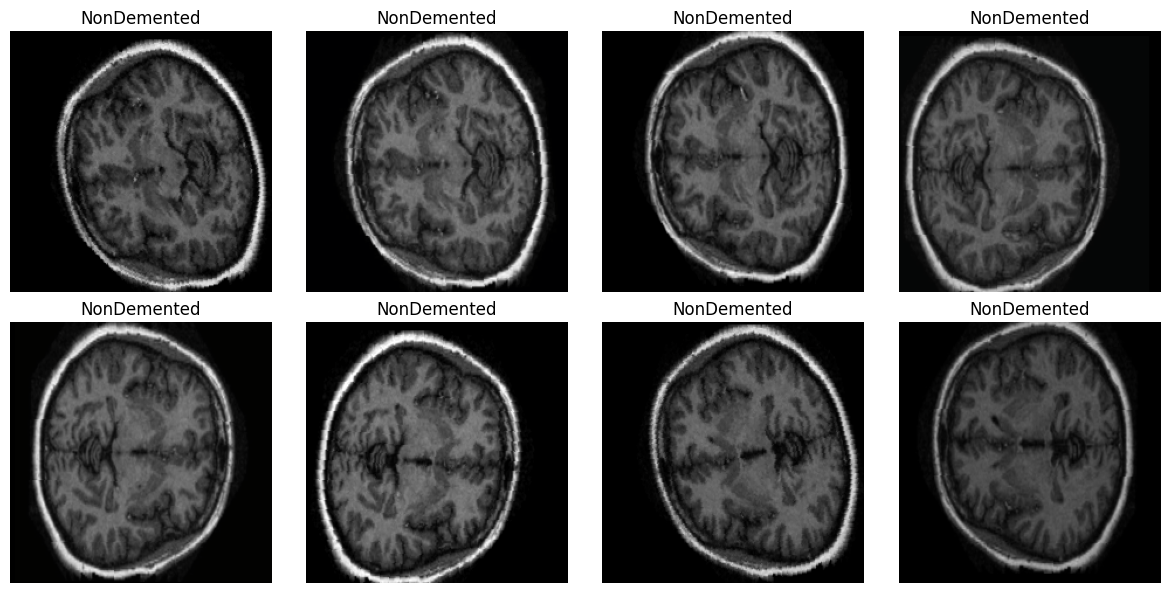

In [7]:
plt.figure(figsize=(12, 6))

for i in range(min(8, len(X_train))):
    plt.subplot(2, 4, i + 1)
    img = X_train[i]

    # Normalize display if tensor is not already in 0-255 range.
    display_img = img.copy()
    if display_img.max() <= 1.5:
        display_img = display_img
    else:
        display_img = display_img / 255.0

    plt.imshow(np.clip(display_img, 0, 1))
    plt.title(CLASS_NAMES[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.10)
], name="data_augmentation")

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3), name="input_mri")
x = data_augmentation(inputs)

# If the shared preprocessing already normalizes images, this is still usually safe for EfficientNet.
# If performance is poor, try removing preprocess_input and compare.
x = preprocess_input(x)

x = base_model(x, training=False)

x = layers.Conv2D(
    64,
    kernel_size=3,
    padding="same",
    activation="relu",
    name="gradcam_conv"
)(x)

x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.35, name="dropout")(x)
outputs = layers.Dense(N_CLASSES, activation="softmax", name="class_output")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_mri (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gradcam_conv (Conv2D)           │ (None, 7, 7, 64)       │       737,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_output (Dense)            │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,787,175 (18.26 MB)

 Trainable params: 737,604 (2.81 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [9]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_custom_cnn_group_split.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks
)

model = tf.keras.models.load_model("best_custom_cnn_group_split.keras")

Epoch 1/15
641/641 ━━━━━━━━━━━━━━━━━━━━ 250s 369ms/step - accuracy: 0.4107 - loss: 1.2843 - val_accuracy: 0.6357 - val_loss: 0.8653 - learning_rate: 0.0010
Epoch 2/15
641/641 ━━━━━━━━━━━━━━━━━━━━ 276s 431ms/step - accuracy: 0.5519 - loss: 0.8965 - val_accuracy: 0.6227 - val_loss: 0.8082 - learning_rate: 0.0010
Epoch 3/15
641/641 ━━━━━━━━━━━━━━━━━━━━ 277s 432ms/step - accuracy: 0.6084 - loss: 0.7225 - val_accuracy: 0.6676 - val_loss: 0.7598 - learning_rate: 0.0010
Epoch 4/15
641/641 ━━━━━━━━━━━━━━━━━━━━ 288s 449ms/step - accuracy: 0.6470 - loss: 0.7052 - val_accuracy: 0.6822 - val_loss: 0.7171 - learning_rate: 0.0010
Epoch 5/15
641/641 ━━━━━━━━━━━━━━━━━━━━ 287s 447ms/step - accuracy: 0.6949 - loss: 0.5795 - val_accuracy: 0.6578 - val_loss: 0.7926 - learning_rate: 0.0010
Epoch 6/15
641/641 ━━━━━━━━━━━━━━━━━━━━ 308s 480ms/step - accuracy: 0.7063 - loss: 0.5536 - val_accuracy: 0.6607 - val_loss: 0.8488 - learning_rate: 0.0010
Epoch 7/15
641/641 ━━━━━━━━━━━━━━━━━━━━ 330s 515ms/step - accura

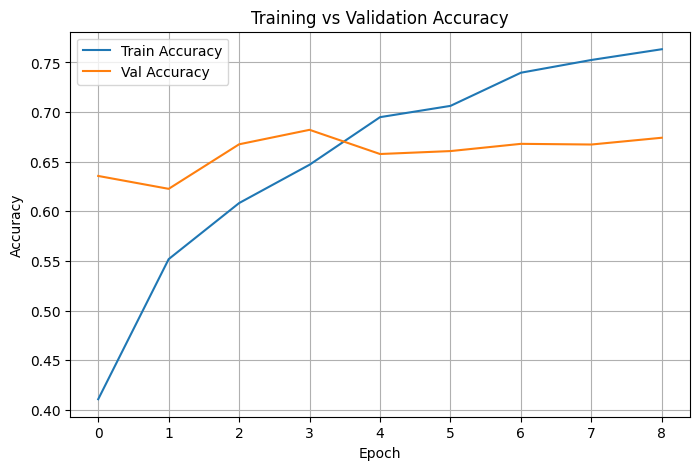

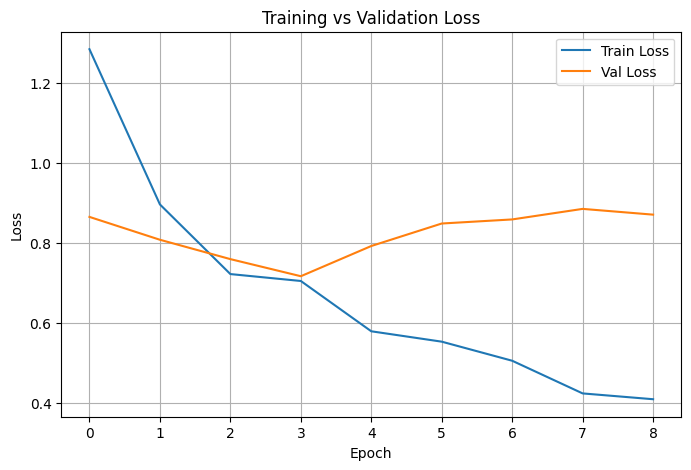

In [10]:
def plot_training_curves(history):
    hist = history.history

    plt.figure(figsize=(8, 5))
    plt.plot(hist["accuracy"], label="Train Accuracy")
    plt.plot(hist["val_accuracy"], label="Val Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Training vs Validation Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(hist["loss"], label="Train Loss")
    plt.plot(hist["val_loss"], label="Val Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_training_curves(history)

In [11]:
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(f"Test Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Test Macro F1: {f1_score(y_true, y_pred, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nActual test supports:")
for i, cls in enumerate(CLASS_NAMES):
    print(f"{cls}: {np.sum(y_true == i)}")

Test Accuracy: 0.7541
Test Macro F1: 0.2813

Classification Report:
                  precision    recall  f1-score   support

    MildDemented     0.0000    0.0000    0.0000       147
ModerateDemented     0.0000    0.0000    0.0000        84
     NonDemented     0.8454    0.9030    0.8732      3906
VeryMildDemented     0.3403    0.2000    0.2519       735

        accuracy                         0.7541      4872
       macro avg     0.2964    0.2757    0.2813      4872
    weighted avg     0.7291    0.7541    0.7381      4872

Confusion Matrix:
[[   0    0  121   26]
 [  29    0   55    0]
 [ 114    6 3527  259]
 [ 113    6  469  147]]

Actual test supports:
MildDemented: 147
ModerateDemented: 84
NonDemented: 3906
VeryMildDemented: 735


2026-06-09 00:20:45.361787: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


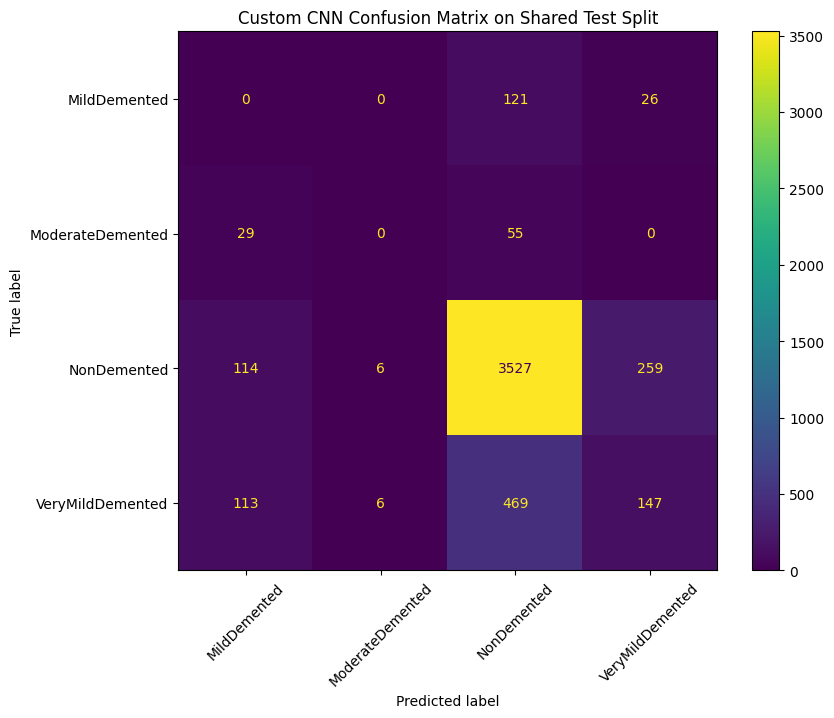

In [12]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45, values_format="d")
plt.title("Custom CNN Confusion Matrix on Shared Test Split")
plt.show()

In [13]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name="gradcam_conv", pred_index=None):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    max_val = tf.reduce_max(heatmap)

    if max_val == 0:
        return np.zeros_like(heatmap.numpy()), predictions.numpy()

    heatmap = tf.maximum(heatmap, 0) / max_val
    return heatmap.numpy(), predictions.numpy()


def show_gradcam(image, true_label=None, alpha=0.4):
    img_array = tf.expand_dims(image, axis=0)

    heatmap, predictions = make_gradcam_heatmap(
        img_array,
        model,
        last_conv_layer_name="gradcam_conv"
    )

    pred_idx = int(np.argmax(predictions[0]))
    pred_name = CLASS_NAMES[pred_idx]
    confidence = float(predictions[0][pred_idx])

    image_np = image.copy()

    # Convert for display.
    display_img = image_np.copy()
    if display_img.max() > 1.5:
        display_img = display_img / 255.0
    display_img = np.clip(display_img, 0, 1)

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (display_img.shape[0], display_img.shape[1])
    ).numpy().squeeze()

    true_text = ""
    if true_label is not None:
        true_text = f"True: {CLASS_NAMES[int(true_label)]}\n"

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(display_img)
    plt.title("Original MRI")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(display_img)
    plt.imshow(heatmap_resized, cmap="jet", alpha=alpha)
    plt.title(f"{true_text}Pred: {pred_name}\nConfidence: {confidence:.2f}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

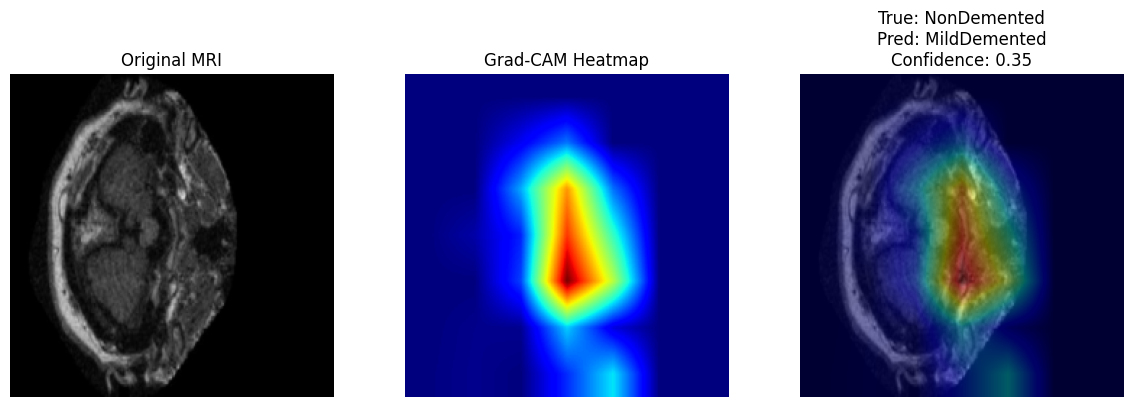

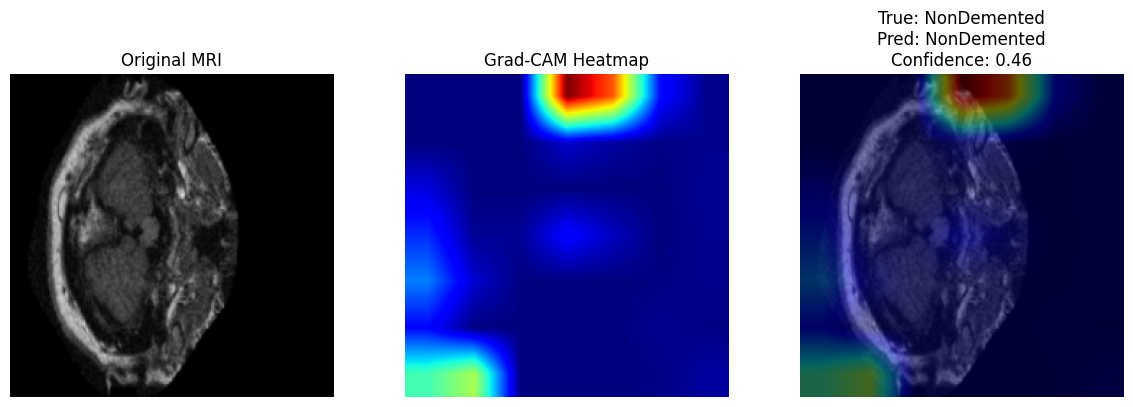

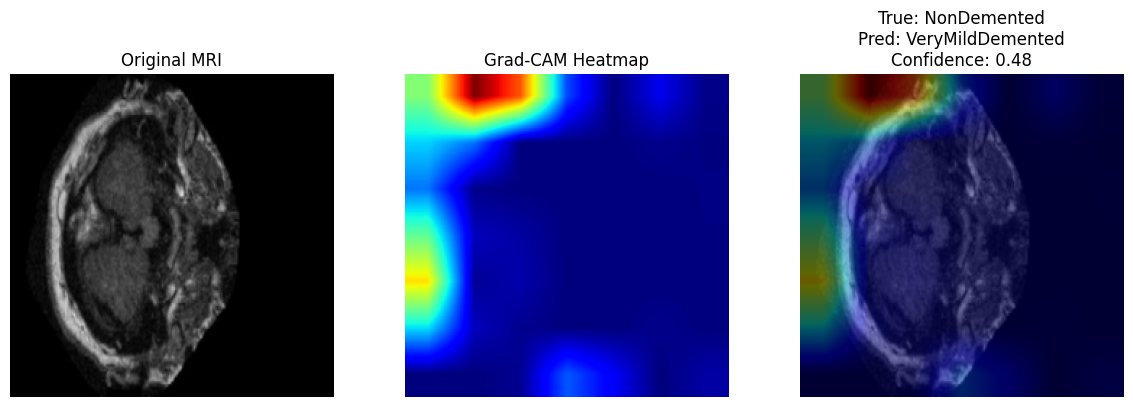

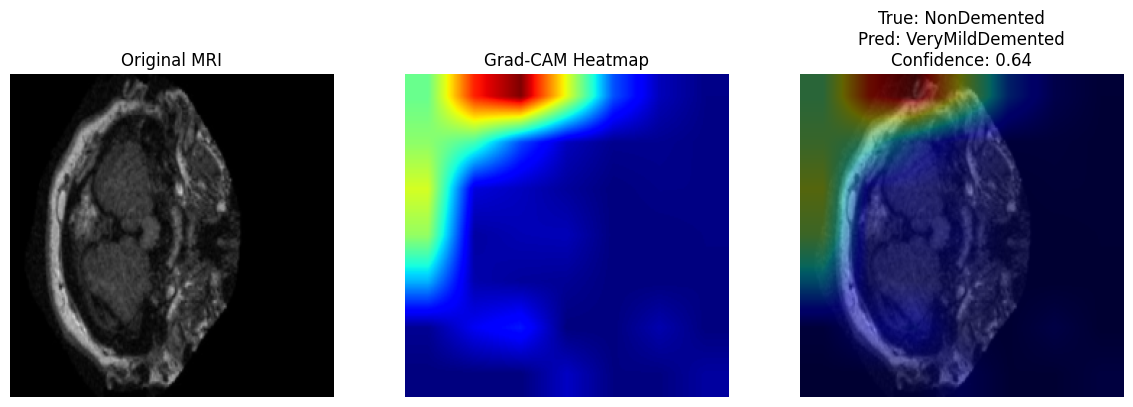

In [14]:
for i in range(min(4, len(X_test))):
    show_gradcam(X_test[i], true_label=y_test[i])

## 15. Notes for the final report

Use these points in your final report:

- We used the shared group preprocessing script to ensure identical preprocessing across models.
- We filtered to axial/top-view images only using `filter_axial=True`.
- We used the shared patient-level split from `split_indices.json`, which prevents the same patient from appearing across train/validation/test sets.
- The split is 70% train, 15% validation, and 15% test.
- We used weighted cross-entropy through Keras `class_weight`, using the loss weights returned by the shared preprocessing pipeline.
- The primary metric is Macro F1 because accuracy can be misleading under severe class imbalance.
- Grad-CAM was used to visualize the regions that influenced the model's predictions.